# Credit EDA Project
### Exploratory Data Analysis of Credit Card Client Behavior

This notebook performs a complete exploratory data analysis of the **Default of Credit Card Clients** dataset from the UCI Machine Learning Repository.

The analysis examines:

- Customer demographics
- Credit-limit distribution
- Repayment-status patterns
- Monthly bill amounts
- Monthly payment amounts
- Default-payment distribution
- Relationships between customer characteristics and default behavior
- Correlations among numerical variables
- Interactive filtered exploration through a dashboard

This is an **EDA-only project**. It does not train or evaluate a prediction model.

## Project Objectives

1. Load a real public credit dataset from an authoritative source.
2. Validate its shape, columns, data types, missing values, and duplicate records.
3. Convert encoded demographic variables into readable categories.
4. Explore customer profiles, credit limits, repayment history, bills, and payments.
5. Compare clients who defaulted with clients who did not default.
6. Create clear statistical summaries and visualizations.
7. Provide an interactive dashboard for manual exploration.

## Section 1 - Environment Setup

In [ ]:
# Check the external packages required by this EDA notebook.
from importlib import metadata  # Reads installed-package information.
import subprocess  # Runs package installation commands when necessary.
import sys  # Provides the current Python interpreter path.

required_packages = [  # Lists all third-party packages used in the project.
    "ucimlrepo",  # Downloads the official UCI credit dataset.
    "pandas",  # Stores and analyzes tabular data.
    "numpy",  # Performs numerical calculations.
    "matplotlib",  # Creates static visualizations.
    "seaborn",  # Creates statistical charts.
    "ipywidgets",  # Creates the interactive EDA dashboard.
]  # Ends the package list.

missing_packages = []  # Stores packages that are unavailable.
for package_name in required_packages:  # Checks every required package.
    try:  # Starts a protected package lookup.
        metadata.version(package_name)  # Reads the installed package version.
    except metadata.PackageNotFoundError:  # Handles a package that is not installed.
        missing_packages.append(package_name)  # Adds the package to the installation list.

if missing_packages:  # Installs only packages that are missing.
    print("Installing missing packages:", missing_packages)  # Displays the installation list.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing_packages)  # Installs into the active environment.
else:  # Handles an already prepared environment.
    print("All required packages are available.")  # Confirms that setup is complete.

Installing missing packages: ['ucimlrepo']


In [ ]:
import warnings  # Controls non-critical warning messages.
warnings.filterwarnings("ignore")  # Keeps the notebook output focused on EDA results.

import numpy as np  # Performs numerical calculations.
import pandas as pd  # Provides DataFrame operations.
import matplotlib.pyplot as plt  # Creates figures and axes.
import seaborn as sns  # Creates statistical visualizations.

from ucimlrepo import fetch_ucirepo  # Retrieves datasets from the official UCI repository.
from IPython.display import display, HTML, clear_output  # Displays tables and dashboard content.
import ipywidgets as widgets  # Provides interactive controls.

SEED = 42  # Defines a reproducibility seed for sampling operations.
np.random.seed(SEED)  # Fixes NumPy random behavior.
pd.set_option("display.max_columns", 40)  # Shows all relevant DataFrame columns.
sns.set_theme(style="whitegrid", palette="deep")  # Applies a consistent visualization theme.

COLORS = {  # Defines a reusable color palette for the project.
    "primary": "#295F78",  # Uses deep blue for main information.
    "secondary": "#6A9C89",  # Uses green for supporting information.
    "accent": "#E9B44C",  # Uses amber for emphasis.
    "danger": "#C8553D",  # Uses red for default-related information.
    "light": "#EDF4F6",  # Uses pale blue for backgrounds.
}  # Ends the color palette.

print("Pandas version:", pd.__version__)  # Displays the active pandas version.

Pandas version: 2.2.3


## Section 2 - Dataset Source and Loading

**Dataset:** Default of Credit Card Clients  
**Source:** UCI Machine Learning Repository  
**Dataset page:** https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients  
**DOI:** https://doi.org/10.24432/C55S3H

The dataset contains 30,000 credit-card clients from Taiwan. It includes demographic information, credit limits, repayment status, six months of bill amounts, six months of payment amounts, and the next-month default outcome.

In [ ]:
credit_repository = fetch_ucirepo(id=350)  # Downloads the official UCI dataset by its stable identifier.
features_df = credit_repository.data.features.copy()  # Copies the 23 explanatory variables.
target_df = credit_repository.data.targets.copy()  # Copies the default-payment target variable.

credit_df = pd.concat([features_df, target_df], axis=1)  # Combines features and target into one table.

rename_map = {  # Converts encoded UCI column names into readable business names.
    "X1": "LIMIT_BAL",  # Stores the granted credit limit.
    "X2": "SEX",  # Stores the encoded client sex.
    "X3": "EDUCATION",  # Stores the encoded education level.
    "X4": "MARRIAGE",  # Stores the encoded marital status.
    "X5": "AGE",  # Stores age in years.
    "X6": "PAY_0",  # Stores September repayment status.
    "X7": "PAY_2",  # Stores August repayment status.
    "X8": "PAY_3",  # Stores July repayment status.
    "X9": "PAY_4",  # Stores June repayment status.
    "X10": "PAY_5",  # Stores May repayment status.
    "X11": "PAY_6",  # Stores April repayment status.
    "X12": "BILL_AMT1",  # Stores September bill amount.
    "X13": "BILL_AMT2",  # Stores August bill amount.
    "X14": "BILL_AMT3",  # Stores July bill amount.
    "X15": "BILL_AMT4",  # Stores June bill amount.
    "X16": "BILL_AMT5",  # Stores May bill amount.
    "X17": "BILL_AMT6",  # Stores April bill amount.
    "X18": "PAY_AMT1",  # Stores September payment amount.
    "X19": "PAY_AMT2",  # Stores August payment amount.
    "X20": "PAY_AMT3",  # Stores July payment amount.
    "X21": "PAY_AMT4",  # Stores June payment amount.
    "X22": "PAY_AMT5",  # Stores May payment amount.
    "X23": "PAY_AMT6",  # Stores April payment amount.
    "Y": "DEFAULT",  # Stores the next-month default indicator.
}  # Ends the column-name mapping.

credit_df = credit_df.rename(columns=rename_map)  # Applies readable column names.

possible_target_names = [  # Lists target names used by different UCI package versions.
    "default payment next month",  # Handles the descriptive target name.
    "default.payment.next.month",  # Handles a dotted target name.
]  # Ends the alternative target-name list.
for target_name in possible_target_names:  # Checks every possible target name.
    if target_name in credit_df.columns:  # Detects a target name that needs standardization.
        credit_df = credit_df.rename(columns={target_name: "DEFAULT"})  # Renames it to the project standard.

assert "DEFAULT" in credit_df.columns, "The default target column was not found."  # Stops if the UCI schema changed unexpectedly.
print("Dataset shape:", credit_df.shape)  # Displays rows and columns.
credit_df.head()  # Displays the first five records.

Dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Section 3 - Data Quality Assessment

In [ ]:
quality_summary = pd.DataFrame({  # Creates a column-level quality report.
    "Data Type": credit_df.dtypes.astype(str),  # Records every column data type.
    "Missing Values": credit_df.isna().sum(),  # Counts missing values per column.
    "Unique Values": credit_df.nunique(),  # Counts distinct values per column.
})  # Finishes the quality summary.

duplicate_rows = int(credit_df.duplicated().sum())  # Counts completely duplicated client records.

print("Rows:", credit_df.shape[0])  # Displays the number of clients.
print("Columns:", credit_df.shape[1])  # Displays the number of variables.
print("Total missing values:", int(credit_df.isna().sum().sum()))  # Displays the complete missing-value count.
print("Duplicate rows:", duplicate_rows)  # Displays the duplicate-record count.
display(quality_summary)  # Displays the detailed quality table.

Rows: 30000
Columns: 24
Total missing values: 0
Duplicate rows: 35


,Data Type,Missing Values,Unique Values
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_0,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11
PAY_5,int64,0,10


In [ ]:
numeric_summary = credit_df.describe().T  # Calculates descriptive statistics for numerical variables.
numeric_summary["range"] = numeric_summary["max"] - numeric_summary["min"]  # Adds the observed numeric range.
display(numeric_summary.round(2))  # Displays rounded descriptive statistics.

,count,mean,std,min,25%,50%,75%,max,range
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,990000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0,1.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,58.0
PAY_0,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0,10.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0,10.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0,10.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0,10.0
PAY_5,30000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0,10.0


## Section 4 - Data Preparation and Readable Labels

The original dataset uses numeric codes for sex, education, marital status, repayment status, and default outcome. This section preserves the raw numerical columns and adds readable labels for interpretation.

In [ ]:
eda_df = credit_df.copy()  # Preserves the original loaded table before adding EDA features.

eda_df["EDUCATION"] = eda_df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})  # Groups undocumented education codes into Other.
eda_df["MARRIAGE"] = eda_df["MARRIAGE"].replace({0: 3})  # Groups the undocumented marital code into Other.

sex_labels = {1: "Male", 2: "Female"}  # Defines readable sex labels.
education_labels = {1: "Graduate School", 2: "University", 3: "High School", 4: "Other"}  # Defines education labels.
marriage_labels = {1: "Married", 2: "Single", 3: "Other"}  # Defines marital-status labels.
default_labels = {0: "No Default", 1: "Default"}  # Defines target labels.

eda_df["SEX_LABEL"] = eda_df["SEX"].map(sex_labels)  # Adds readable sex values.
eda_df["EDUCATION_LABEL"] = eda_df["EDUCATION"].map(education_labels)  # Adds readable education values.
eda_df["MARRIAGE_LABEL"] = eda_df["MARRIAGE"].map(marriage_labels)  # Adds readable marital values.
eda_df["DEFAULT_LABEL"] = eda_df["DEFAULT"].map(default_labels)  # Adds readable default values.

eda_df["AGE_GROUP"] = pd.cut(  # Creates interpretable age bands.
    eda_df["AGE"],  # Supplies client ages.
    bins=[20, 29, 39, 49, 59, 69, 100],  # Defines age boundaries.
    labels=["21-29", "30-39", "40-49", "50-59", "60-69", "70+"],  # Names each age band.
    include_lowest=True,  # Includes the youngest observed clients.
)  # Finishes age grouping.

eda_df["LIMIT_GROUP"] = pd.cut(  # Creates credit-limit bands.
    eda_df["LIMIT_BAL"],  # Supplies granted credit limits.
    bins=[-np.inf, 50000, 100000, 200000, 500000, np.inf],  # Defines credit-limit boundaries.
    labels=["Up to 50K", "50K-100K", "100K-200K", "200K-500K", "Above 500K"],  # Names each band.
)  # Finishes credit-limit grouping.

pay_status_columns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]  # Lists repayment-status months.
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]  # Lists six bill-amount columns.
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]  # Lists six payment-amount columns.

eda_df["AVG_BILL"] = eda_df[bill_columns].mean(axis=1)  # Calculates each client's average monthly bill.
eda_df["AVG_PAYMENT"] = eda_df[payment_columns].mean(axis=1)  # Calculates each client's average monthly payment.
eda_df["MAX_DELAY"] = eda_df[pay_status_columns].max(axis=1)  # Finds the most severe repayment delay.
eda_df["MONTHS_DELAYED"] = (eda_df[pay_status_columns] > 0).sum(axis=1)  # Counts months with positive delay codes.
eda_df["UTILIZATION_PROXY"] = eda_df["AVG_BILL"].clip(lower=0) / eda_df["LIMIT_BAL"].replace(0, np.nan)  # Estimates average limit utilization.

display(eda_df[["SEX_LABEL", "EDUCATION_LABEL", "MARRIAGE_LABEL", "AGE_GROUP", "LIMIT_GROUP", "DEFAULT_LABEL"]].head())  # Verifies readable labels.

,SEX_LABEL,EDUCATION_LABEL,MARRIAGE_LABEL,AGE_GROUP,LIMIT_GROUP,DEFAULT_LABEL
0,Female,University,Married,21-29,Up to 50K,Default
1,Female,University,Single,21-29,100K-200K,Default
2,Female,University,Single,30-39,50K-100K,No Default
3,Female,University,Married,30-39,Up to 50K,No Default
4,Male,University,Married,50-59,Up to 50K,No Default


## Section 5 - Default Outcome Overview

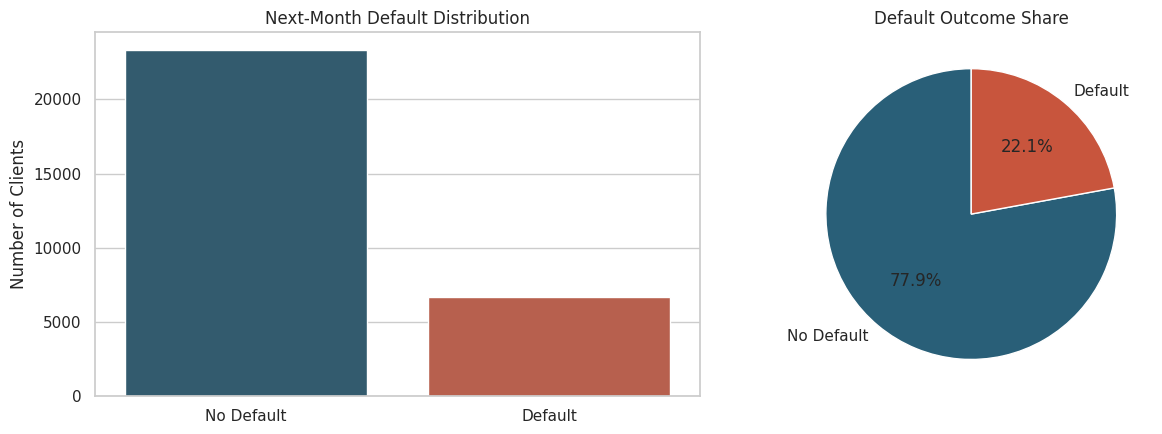

,Count,Percentage
DEFAULT_LABEL,,
No Default,23364,77.88
Default,6636,22.12


In [ ]:
default_counts = eda_df["DEFAULT_LABEL"].value_counts()  # Counts clients in each default outcome.
default_rates = eda_df["DEFAULT_LABEL"].value_counts(normalize=True).mul(100)  # Converts counts into percentages.

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))  # Creates count and percentage visualizations.
sns.countplot(data=eda_df, x="DEFAULT_LABEL", order=["No Default", "Default"], palette=[COLORS["primary"], COLORS["danger"]], ax=axes[0])  # Plots outcome counts.
axes[0].set_title("Next-Month Default Distribution")  # Adds the count-chart title.
axes[0].set_xlabel("")  # Removes the redundant horizontal label.
axes[0].set_ylabel("Number of Clients")  # Labels the vertical count axis.

axes[1].pie(default_counts.reindex(["No Default", "Default"]), labels=["No Default", "Default"], autopct="%1.1f%%", colors=[COLORS["primary"], COLORS["danger"]], startangle=90, wedgeprops={"edgecolor": "white"})  # Plots outcome percentages.
axes[1].set_title("Default Outcome Share")  # Adds the percentage-chart title.

plt.tight_layout()  # Prevents chart overlap.
plt.show()  # Displays both outcome charts.
display(pd.DataFrame({"Count": default_counts, "Percentage": default_rates.round(2)}))  # Displays exact outcome values.

## Section 6 - Customer Demographic Analysis

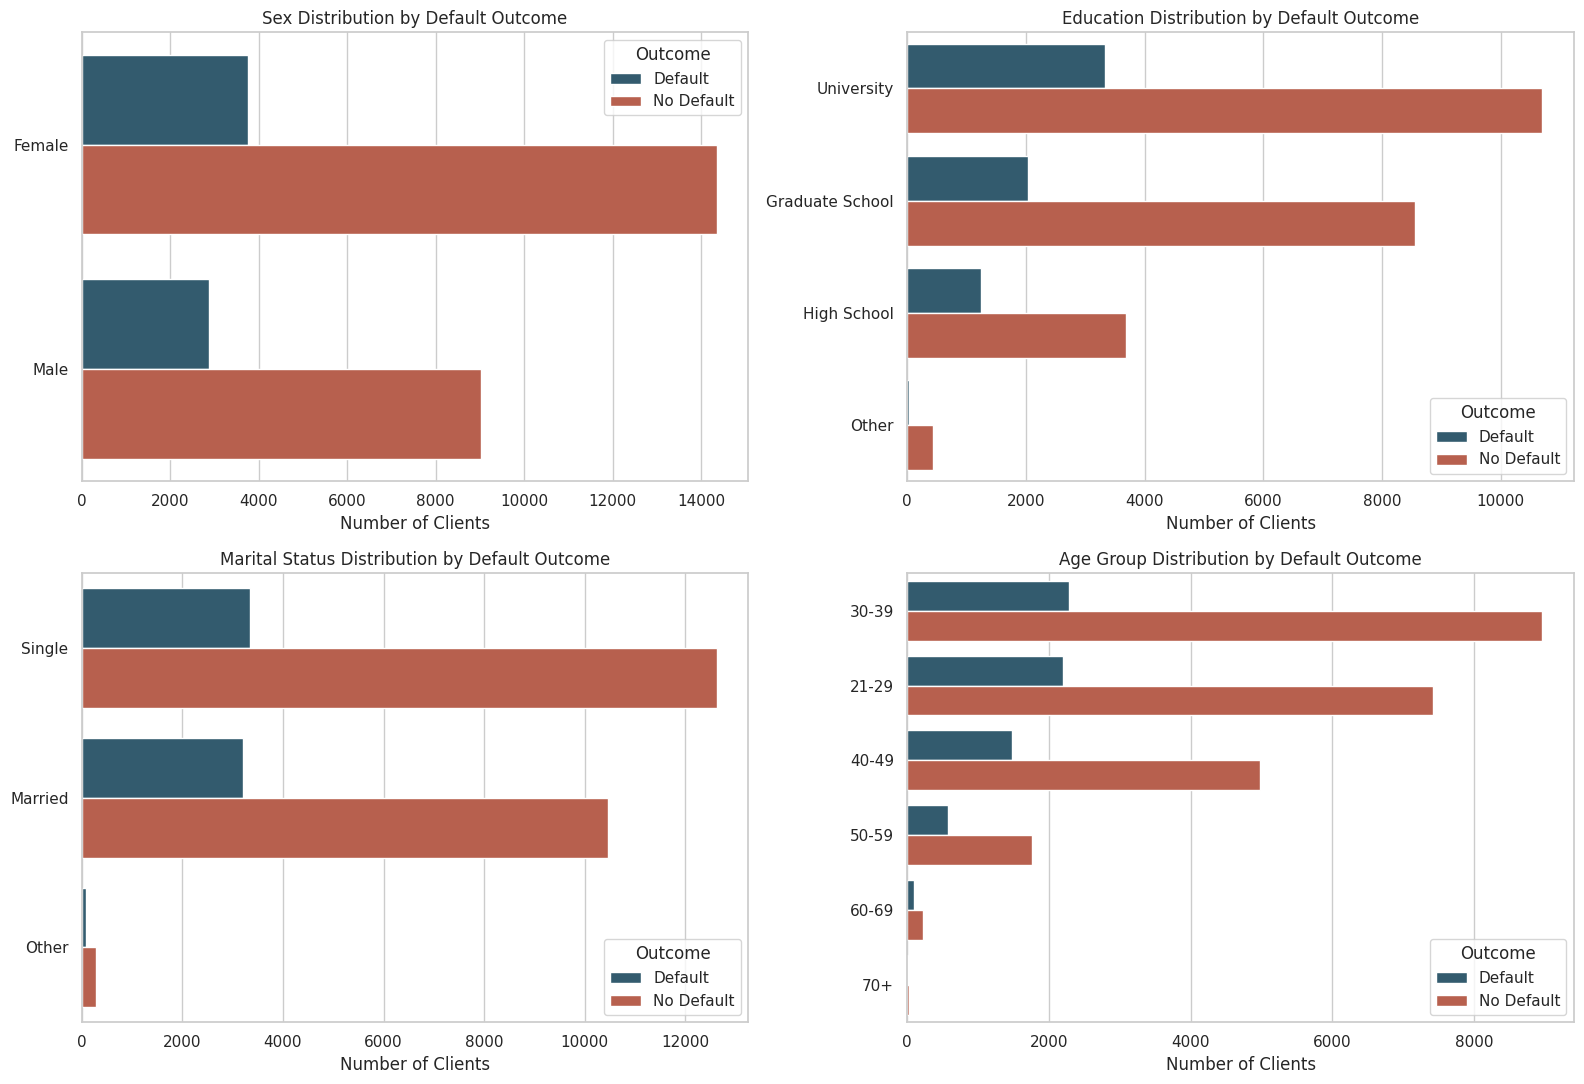

In [ ]:
demographic_columns = ["SEX_LABEL", "EDUCATION_LABEL", "MARRIAGE_LABEL", "AGE_GROUP"]  # Lists categorical profile variables.
demographic_titles = ["Sex", "Education", "Marital Status", "Age Group"]  # Defines readable chart titles.

figure, axes = plt.subplots(2, 2, figsize=(16, 11))  # Creates a four-chart demographic layout.
for axis, column, title in zip(axes.flatten(), demographic_columns, demographic_titles):  # Processes every demographic feature.
    order = eda_df[column].value_counts().index  # Orders categories by frequency.
    sns.countplot(data=eda_df, y=column, hue="DEFAULT_LABEL", order=order, palette=[COLORS["primary"], COLORS["danger"]], ax=axis)  # Compares default outcomes within the feature.
    axis.set_title(f"{title} Distribution by Default Outcome")  # Adds a descriptive chart title.
    axis.set_xlabel("Number of Clients")  # Labels the horizontal count axis.
    axis.set_ylabel("")  # Removes the technical column name.
    axis.legend(title="Outcome")  # Labels the chart legend.

plt.tight_layout()  # Prevents subplot overlap.
plt.show()  # Displays the demographic analysis.

In [ ]:
def category_default_table(column):  # Defines a reusable categorical default-rate summary.
    summary = eda_df.groupby(column, observed=False).agg(  # Groups clients by the selected category.
        Clients=("DEFAULT", "size"),  # Counts clients in every category.
        Defaults=("DEFAULT", "sum"),  # Counts defaults in every category.
        Default_Rate=("DEFAULT", "mean"),  # Calculates category-level default rate.
    ).reset_index()  # Converts grouped labels back into columns.
    summary["Default_Rate"] = summary["Default_Rate"].mul(100).round(2)  # Converts rates to percentages.
    return summary.sort_values("Default_Rate", ascending=False)  # Returns highest-risk categories first.

display(category_default_table("EDUCATION_LABEL"))  # Displays education-level default rates.
display(category_default_table("AGE_GROUP"))  # Displays age-group default rates.
display(category_default_table("LIMIT_GROUP"))  # Displays credit-limit-group default rates.

,EDUCATION_LABEL,Clients,Defaults,Default_Rate
1,High School,4917,1237,25.16
3,University,14030,3330,23.73
0,Graduate School,10585,2036,19.23
2,Other,468,33,7.05


,AGE_GROUP,Clients,Defaults,Default_Rate
4,60-69,314,89,28.34
5,70+,25,7,28.00
3,50-59,2341,582,24.86
2,40-49,6464,1485,22.97
0,21-29,9618,2197,22.84
1,30-39,11238,2276,20.25


,LIMIT_GROUP,Clients,Defaults,Default_Rate
0,Up to 50K,7676,2440,31.79
1,50K-100K,4822,1244,25.80
2,100K-200K,7880,1535,19.48
3,200K-500K,9416,1394,14.80
4,Above 500K,206,23,11.17


## Section 7 - Credit Limit and Age Distributions

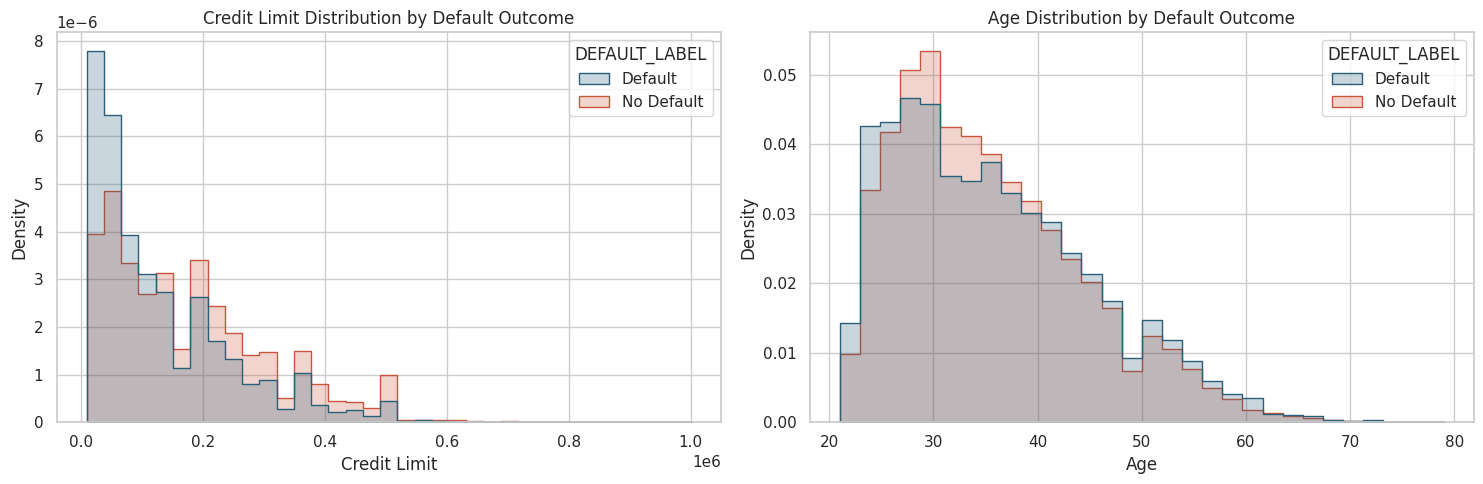

In [ ]:
figure, axes = plt.subplots(1, 2, figsize=(15, 5))  # Creates credit-limit and age charts.
sns.histplot(data=eda_df, x="LIMIT_BAL", hue="DEFAULT_LABEL", bins=35, element="step", stat="density", common_norm=False, palette=[COLORS["primary"], COLORS["danger"]], ax=axes[0])  # Compares credit-limit distributions.
axes[0].set_title("Credit Limit Distribution by Default Outcome")  # Adds the credit-limit title.
axes[0].set_xlabel("Credit Limit")  # Labels the credit-limit axis.
axes[0].set_ylabel("Density")  # Labels the density axis.

sns.histplot(data=eda_df, x="AGE", hue="DEFAULT_LABEL", bins=30, element="step", stat="density", common_norm=False, palette=[COLORS["primary"], COLORS["danger"]], ax=axes[1])  # Compares age distributions.
axes[1].set_title("Age Distribution by Default Outcome")  # Adds the age-chart title.
axes[1].set_xlabel("Age")  # Labels the age axis.
axes[1].set_ylabel("Density")  # Labels the density axis.

plt.tight_layout()  # Prevents chart overlap.
plt.show()  # Displays both distribution charts.

## Section 8 - Repayment Status Analysis

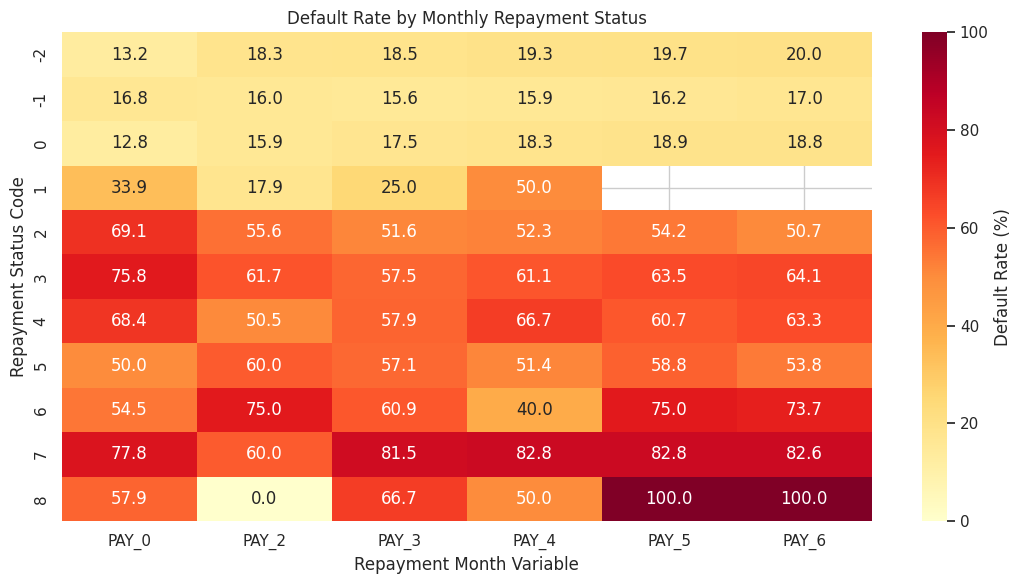

In [ ]:
repayment_default_rates = []  # Collects default rates for every month and repayment code.
for column in pay_status_columns:  # Processes each monthly repayment-status column.
    monthly_summary = eda_df.groupby(column)["DEFAULT"].agg(["count", "mean"]).reset_index()  # Calculates count and default rate by status.
    monthly_summary["Month"] = column  # Records the source repayment month.
    monthly_summary = monthly_summary.rename(columns={column: "Repayment_Status", "count": "Clients", "mean": "Default_Rate"})  # Applies readable summary names.
    repayment_default_rates.append(monthly_summary)  # Stores the monthly summary.

repayment_risk_df = pd.concat(repayment_default_rates, ignore_index=True)  # Combines all monthly summaries.
repayment_pivot = repayment_risk_df.pivot(index="Repayment_Status", columns="Month", values="Default_Rate").mul(100)  # Creates a heatmap-ready percentage table.

plt.figure(figsize=(11, 6))  # Creates the repayment-risk figure.
sns.heatmap(repayment_pivot, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Default Rate (%)"})  # Visualizes default rate by month and delay code.
plt.title("Default Rate by Monthly Repayment Status")  # Adds the heatmap title.
plt.xlabel("Repayment Month Variable")  # Labels the horizontal axis.
plt.ylabel("Repayment Status Code")  # Labels the vertical axis.
plt.tight_layout()  # Prevents label clipping.
plt.show()  # Displays the repayment-status heatmap.

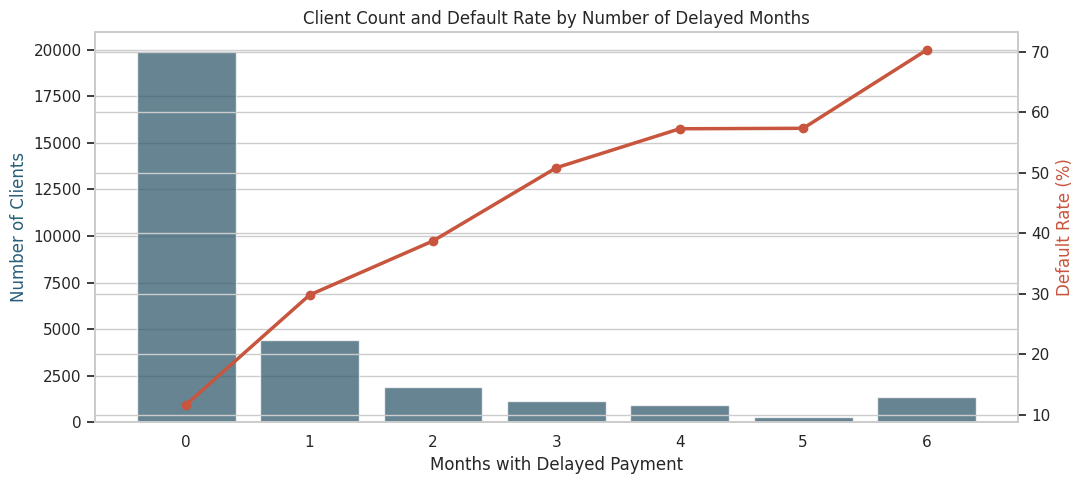

,MONTHS_DELAYED,Clients,Default_Rate
0,0,19931,11.71
1,1,4426,29.82
2,2,1899,38.76
3,3,1154,50.87
4,4,951,57.31
5,5,298,57.38
6,6,1341,70.32


In [ ]:
delay_summary = eda_df.groupby("MONTHS_DELAYED").agg(  # Groups clients by the number of delayed months.
    Clients=("DEFAULT", "size"),  # Counts clients in each group.
    Default_Rate=("DEFAULT", "mean"),  # Calculates the group default rate.
).reset_index()  # Converts group labels into a normal column.
delay_summary["Default_Rate"] = delay_summary["Default_Rate"].mul(100)  # Converts default rate to percentage.

figure, axis_left = plt.subplots(figsize=(11, 5))  # Creates a combined count and rate figure.
sns.barplot(data=delay_summary, x="MONTHS_DELAYED", y="Clients", color=COLORS["primary"], alpha=0.75, ax=axis_left)  # Plots client counts.
axis_left.set_title("Client Count and Default Rate by Number of Delayed Months")  # Adds the chart title.
axis_left.set_xlabel("Months with Delayed Payment")  # Labels the horizontal axis.
axis_left.set_ylabel("Number of Clients", color=COLORS["primary"])  # Labels the left count axis.

axis_right = axis_left.twinx()  # Creates a second vertical axis for percentage.
axis_right.plot(delay_summary["MONTHS_DELAYED"], delay_summary["Default_Rate"], marker="o", linewidth=2.5, color=COLORS["danger"])  # Plots default rates.
axis_right.set_ylabel("Default Rate (%)", color=COLORS["danger"])  # Labels the right percentage axis.
plt.tight_layout()  # Prevents clipping.
plt.show()  # Displays the combined repayment chart.
display(delay_summary.round(2))  # Displays exact count and rate values.

## Section 9 - Monthly Bill and Payment Analysis

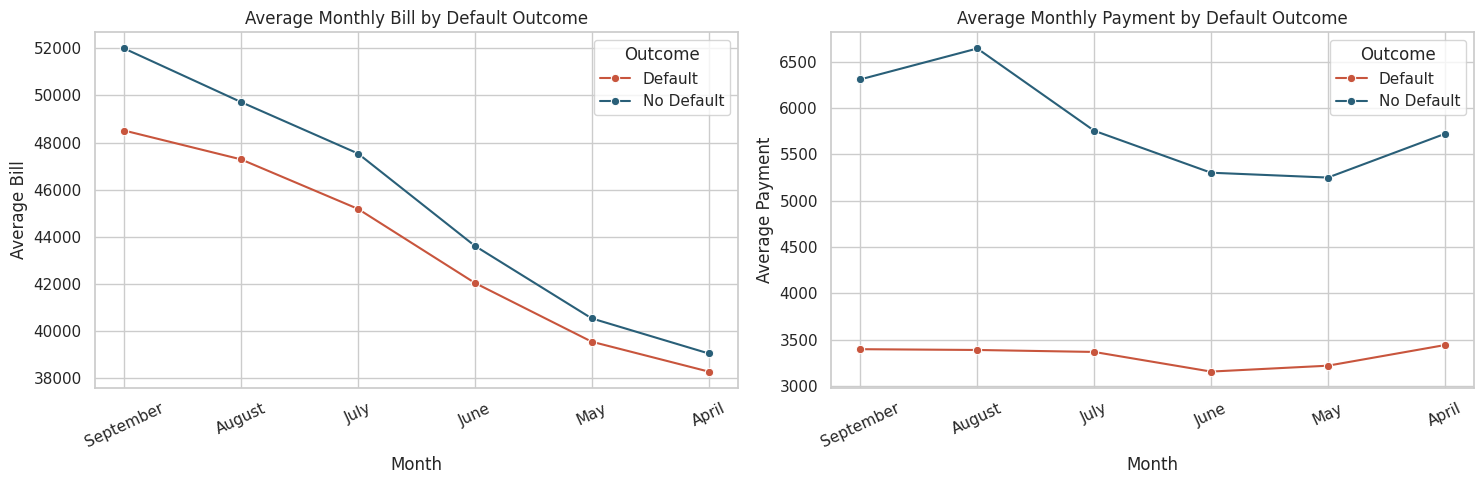

In [ ]:
month_labels = ["September", "August", "July", "June", "May", "April"]  # Defines chronological labels used by the source columns.
trend_rows = []  # Collects outcome-level monthly averages.
for outcome_name, outcome_group in eda_df.groupby("DEFAULT_LABEL"):  # Processes default and non-default clients separately.
    for month_index, month_name in enumerate(month_labels, start=1):  # Processes all six months.
        trend_rows.append({  # Adds one monthly summary record.
            "Outcome": outcome_name,  # Stores the default outcome.
            "Month": month_name,  # Stores the readable month.
            "Average Bill": outcome_group[f"BILL_AMT{month_index}"].mean(),  # Calculates average billed amount.
            "Average Payment": outcome_group[f"PAY_AMT{month_index}"].mean(),  # Calculates average paid amount.
        })  # Finishes the monthly record.

trend_df = pd.DataFrame(trend_rows)  # Converts trend records into a DataFrame.

figure, axes = plt.subplots(1, 2, figsize=(15, 5))  # Creates bill and payment trend charts.
sns.lineplot(data=trend_df, x="Month", y="Average Bill", hue="Outcome", marker="o", palette=[COLORS["danger"], COLORS["primary"]], ax=axes[0])  # Plots average bills.
axes[0].set_title("Average Monthly Bill by Default Outcome")  # Adds the bill-trend title.
axes[0].tick_params(axis="x", rotation=25)  # Rotates month labels.

sns.lineplot(data=trend_df, x="Month", y="Average Payment", hue="Outcome", marker="o", palette=[COLORS["danger"], COLORS["primary"]], ax=axes[1])  # Plots average payments.
axes[1].set_title("Average Monthly Payment by Default Outcome")  # Adds the payment-trend title.
axes[1].tick_params(axis="x", rotation=25)  # Rotates month labels.

plt.tight_layout()  # Prevents overlap.
plt.show()  # Displays both financial trend charts.

## Section 10 - Correlation Analysis

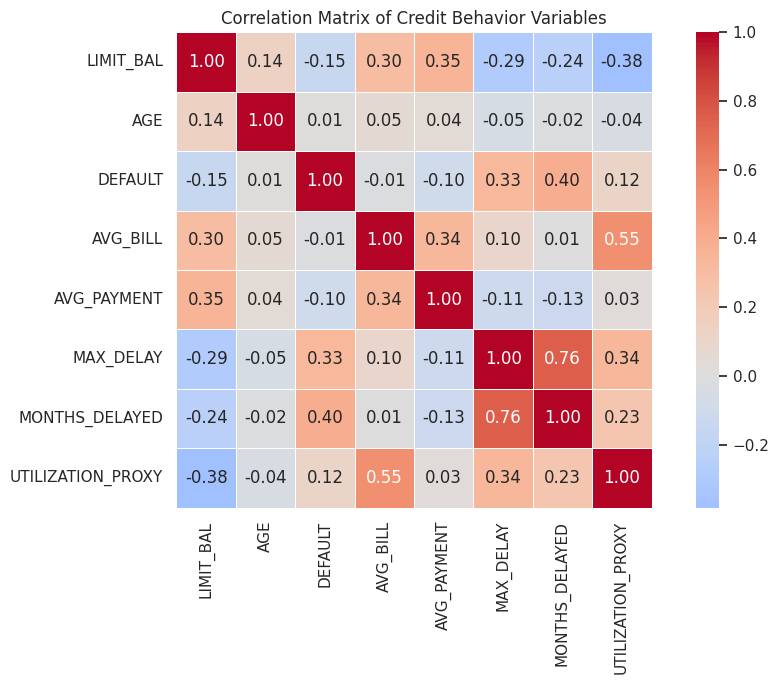

,Correlation with Default
MONTHS_DELAYED,0.398
MAX_DELAY,0.331
LIMIT_BAL,-0.154
UTILIZATION_PROXY,0.116
AVG_PAYMENT,-0.102
AGE,0.014
AVG_BILL,-0.013


In [ ]:
correlation_columns = ["LIMIT_BAL", "AGE", "DEFAULT", "AVG_BILL", "AVG_PAYMENT", "MAX_DELAY", "MONTHS_DELAYED", "UTILIZATION_PROXY"]  # Selects interpretable EDA variables.
correlation_matrix = eda_df[correlation_columns].corr()  # Calculates Pearson correlations.

plt.figure(figsize=(10, 7))  # Creates the correlation figure.
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)  # Draws the annotated matrix.
plt.title("Correlation Matrix of Credit Behavior Variables")  # Adds the matrix title.
plt.tight_layout()  # Prevents label clipping.
plt.show()  # Displays the correlation heatmap.

default_correlations = correlation_matrix["DEFAULT"].drop("DEFAULT").sort_values(key=abs, ascending=False)  # Ranks correlations with default by absolute strength.
display(default_correlations.to_frame("Correlation with Default").round(3))  # Displays the ranked correlation table.

## Section 11 - Summary Profile Comparison

In [ ]:
profile_comparison = eda_df.groupby("DEFAULT_LABEL").agg(  # Compares central behavior statistics by outcome.
    Clients=("DEFAULT", "size"),  # Counts clients in each outcome.
    Median_Age=("AGE", "median"),  # Calculates median age.
    Median_Credit_Limit=("LIMIT_BAL", "median"),  # Calculates median credit limit.
    Median_Average_Bill=("AVG_BILL", "median"),  # Calculates median monthly bill.
    Median_Average_Payment=("AVG_PAYMENT", "median"),  # Calculates median monthly payment.
    Mean_Delayed_Months=("MONTHS_DELAYED", "mean"),  # Calculates average delayed months.
    Mean_Maximum_Delay=("MAX_DELAY", "mean"),  # Calculates average worst delay.
)  # Finishes the grouped comparison.

display(profile_comparison.round(2))  # Displays the final outcome profile table.

,Clients,Median_Age,Median_Credit_Limit,Median_Average_Bill,Median_Average_Payment,Mean_Delayed_Months,Mean_Maximum_Delay
DEFAULT_LABEL,,,,,,,
Default,6636,34.0,90000.0,19781.33,1612.42,2.0,1.27
No Default,23364,34.0,150000.0,21443.42,2754.00,0.5,0.20


## Section 12 - Interactive Credit EDA Dashboard

Use the controls to filter customers by default outcome, sex, education, age, and credit limit. The dashboard recalculates statistics and visualizations from the selected subset. All filter values can be changed manually.

In [ ]:
PRIMARY = COLORS["primary"]  # Reuses the project primary color.
SECONDARY = COLORS["secondary"]  # Reuses the project secondary color.
DANGER = COLORS["danger"]  # Reuses the project default-risk color.
BACKGROUND = COLORS["light"]  # Reuses the project background color.

dashboard_title = widgets.HTML(value=f"""  # Creates the dashboard title panel.
<div style='background:linear-gradient(135deg,{PRIMARY},{SECONDARY});padding:24px;border-radius:18px;color:white;margin-bottom:14px'>
<div style='font-size:12px;letter-spacing:2px;opacity:.85'>EXPLORATORY DATA ANALYSIS</div>
<div style='font-size:29px;font-weight:750;margin-top:5px'>Credit Client Analysis Dashboard</div>
<div style='font-size:14px;margin-top:7px'>Interactive customer, credit, repayment, bill and default exploration</div>
</div>""")  # Finishes the title panel.

outcome_filter = widgets.Dropdown(options=["All", "No Default", "Default"], value="All", description="Outcome:", style={"description_width": "85px"})  # Creates the default filter.
sex_filter = widgets.Dropdown(options=["All"] + sorted(eda_df["SEX_LABEL"].dropna().unique().tolist()), value="All", description="Sex:", style={"description_width": "85px"})  # Creates the sex filter.
education_filter = widgets.Dropdown(options=["All"] + sorted(eda_df["EDUCATION_LABEL"].dropna().unique().tolist()), value="All", description="Education:", style={"description_width": "85px"})  # Creates the education filter.
age_filter = widgets.IntRangeSlider(value=[int(eda_df["AGE"].min()), int(eda_df["AGE"].max())], min=int(eda_df["AGE"].min()), max=int(eda_df["AGE"].max()), step=1, description="Age:", continuous_update=False, style={"description_width": "85px"}, layout=widgets.Layout(width="46%"))  # Creates the age filter.
limit_filter = widgets.IntRangeSlider(value=[int(eda_df["LIMIT_BAL"].min()), int(eda_df["LIMIT_BAL"].max())], min=int(eda_df["LIMIT_BAL"].min()), max=int(eda_df["LIMIT_BAL"].max()), step=10000, description="Credit limit:", continuous_update=False, style={"description_width": "85px"}, layout=widgets.Layout(width="46%"))  # Creates the credit-limit filter.
reset_button = widgets.Button(description="Reset Filters", icon="refresh", button_style="info")  # Creates a filter-reset button.
dashboard_output = widgets.Output()  # Creates the refreshable dashboard output area.


def filtered_credit_data():  # Builds a filtered DataFrame from the current controls.
    filtered = eda_df.copy()  # Starts with all clients.
    if outcome_filter.value != "All":  # Checks whether an outcome filter is active.
        filtered = filtered[filtered["DEFAULT_LABEL"] == outcome_filter.value]  # Applies the selected outcome.
    if sex_filter.value != "All":  # Checks whether a sex filter is active.
        filtered = filtered[filtered["SEX_LABEL"] == sex_filter.value]  # Applies the selected sex.
    if education_filter.value != "All":  # Checks whether an education filter is active.
        filtered = filtered[filtered["EDUCATION_LABEL"] == education_filter.value]  # Applies the selected education level.
    filtered = filtered[filtered["AGE"].between(*age_filter.value)]  # Applies the selected age interval.
    filtered = filtered[filtered["LIMIT_BAL"].between(*limit_filter.value)]  # Applies the selected credit-limit interval.
    return filtered  # Returns the final filtered dataset.


def update_dashboard(_=None):  # Refreshes dashboard metrics and visualizations.
    filtered = filtered_credit_data()  # Reads the currently selected client subset.
    with dashboard_output:  # Directs refreshed content into the dashboard area.
        clear_output(wait=True)  # Removes the previous dashboard display.
        if filtered.empty:  # Handles filters that return no clients.
            display(HTML("<h3 style='color:#C8553D'>No clients match the selected filters.</h3>"))  # Displays a clear empty-result message.
            return  # Stops dashboard calculations for an empty subset.
        client_count = len(filtered)  # Counts selected clients.
        default_rate = filtered["DEFAULT"].mean() * 100  # Calculates selected default rate.
        median_limit = filtered["LIMIT_BAL"].median()  # Calculates selected median credit limit.
        average_delays = filtered["MONTHS_DELAYED"].mean()  # Calculates selected average delayed months.
        display(HTML(f"""  # Displays the four dashboard metric cards.
        <div style='background:{BACKGROUND};padding:16px;border-radius:16px;display:flex;gap:12px;flex-wrap:wrap'>
        <div style='flex:1;min-width:150px;background:white;padding:15px;border-radius:12px;border-top:5px solid {PRIMARY}'><small>CLIENTS</small><div style='font-size:25px;font-weight:750;color:{PRIMARY}'>{client_count:,}</div></div>
        <div style='flex:1;min-width:150px;background:white;padding:15px;border-radius:12px;border-top:5px solid {DANGER}'><small>DEFAULT RATE</small><div style='font-size:25px;font-weight:750;color:{DANGER}'>{default_rate:.1f}%</div></div>
        <div style='flex:1;min-width:150px;background:white;padding:15px;border-radius:12px;border-top:5px solid {SECONDARY}'><small>MEDIAN CREDIT LIMIT</small><div style='font-size:25px;font-weight:750;color:{SECONDARY}'>{median_limit:,.0f}</div></div>
        <div style='flex:1;min-width:150px;background:white;padding:15px;border-radius:12px;border-top:5px solid #E9B44C'><small>AVERAGE DELAYED MONTHS</small><div style='font-size:25px;font-weight:750;color:#B47A12'>{average_delays:.2f}</div></div>
        </div>"""))  # Finishes the metric-card display.
        figure, axes = plt.subplots(1, 3, figsize=(17, 4.8))  # Creates three filtered charts.
        sns.histplot(data=filtered, x="LIMIT_BAL", bins=25, color=PRIMARY, ax=axes[0])  # Plots selected credit limits.
        axes[0].set_title("Credit Limit Distribution")  # Adds the first chart title.
        axes[0].set_xlabel("Credit Limit")  # Labels the first horizontal axis.
        sns.countplot(data=filtered, y="AGE_GROUP", color=SECONDARY, ax=axes[1])  # Plots selected age groups.
        axes[1].set_title("Selected Clients by Age Group")  # Adds the second chart title.
        axes[1].set_xlabel("Clients")  # Labels the second horizontal axis.
        axes[1].set_ylabel("")  # Removes the technical label.
        dashboard_delay = filtered.groupby("MONTHS_DELAYED")["DEFAULT"].mean().mul(100).reset_index()  # Calculates filtered delay-level default rates.
        sns.lineplot(data=dashboard_delay, x="MONTHS_DELAYED", y="DEFAULT", marker="o", color=DANGER, ax=axes[2])  # Plots selected delay risk.
        axes[2].set_title("Default Rate by Delayed Months")  # Adds the third chart title.
        axes[2].set_xlabel("Delayed Months")  # Labels the third horizontal axis.
        axes[2].set_ylabel("Default Rate (%)")  # Labels the third vertical axis.
        plt.tight_layout()  # Prevents chart overlap.
        plt.show()  # Displays the filtered dashboard charts.


def reset_dashboard(_):  # Restores every dashboard control to its full-data value.
    outcome_filter.value = "All"  # Resets the outcome filter.
    sex_filter.value = "All"  # Resets the sex filter.
    education_filter.value = "All"  # Resets the education filter.
    age_filter.value = [int(eda_df["AGE"].min()), int(eda_df["AGE"].max())]  # Resets the age interval.
    limit_filter.value = [int(eda_df["LIMIT_BAL"].min()), int(eda_df["LIMIT_BAL"].max())]  # Resets the credit-limit interval.
    update_dashboard()  # Refreshes the full-data dashboard.


for control in [outcome_filter, sex_filter, education_filter, age_filter, limit_filter]:  # Processes every interactive filter.
    control.observe(lambda change: update_dashboard() if change["name"] == "value" else None, names="value")  # Refreshes after a value change.
reset_button.on_click(reset_dashboard)  # Connects the reset button to its function.

filter_row_one = widgets.HBox([outcome_filter, sex_filter, education_filter, reset_button])  # Arranges categorical filters.
filter_row_two = widgets.HBox([age_filter, limit_filter])  # Arranges numerical range filters.
display(widgets.VBox([dashboard_title, filter_row_one, filter_row_two, dashboard_output]))  # Displays the complete dashboard.
update_dashboard()  # Loads the initial full-data dashboard.

## Section 13 - Evidence-Based EDA Findings

Run the following cell after completing the earlier analysis. It generates findings directly from the current dataset rather than inserting fixed or assumed conclusions.

In [ ]:
overall_default_rate = eda_df["DEFAULT"].mean() * 100  # Calculates the observed overall default rate.
highest_delay_group = category_default_table("LIMIT_GROUP").iloc[0]  # Identifies the credit-limit group with the highest observed default rate.
most_correlated_feature = default_correlations.index[0]  # Identifies the analyzed variable most correlated with default.
most_correlated_value = default_correlations.iloc[0]  # Reads that correlation value.
maximum_delay_rate = delay_summary.loc[delay_summary["Default_Rate"].idxmax()]  # Identifies the delayed-month group with the highest default rate.

print("EDA findings generated from the current data:")  # Introduces the evidence-based findings.
print(f"1. The observed next-month default rate is {overall_default_rate:.2f}%.")  # Reports overall default prevalence.
print(f"2. The highest observed credit-limit-group default rate is {highest_delay_group['Default_Rate']:.2f}% for {highest_delay_group['LIMIT_GROUP']}.")  # Reports the highest-risk limit band.
print(f"3. Among the selected summary variables, {most_correlated_feature} has the strongest absolute correlation with default ({most_correlated_value:.3f}).")  # Reports the leading selected correlation.
print(f"4. Clients with {int(maximum_delay_rate['MONTHS_DELAYED'])} delayed months have the highest observed rate in the delayed-month summary ({maximum_delay_rate['Default_Rate']:.2f}%).")  # Reports the highest observed delayed-month risk.
print("5. These findings describe associations in this dataset and should not be interpreted as causal effects.")  # States the correct analytical limitation.

EDA findings generated from the current data:
1. The observed next-month default rate is 22.12%.
2. The highest observed credit-limit-group default rate is 31.79% for Up to 50K.
3. Among the selected summary variables, MONTHS_DELAYED has the strongest absolute correlation with default (0.398).
4. Clients with 6 delayed months have the highest observed rate in the delayed-month summary (70.32%).
5. These findings describe associations in this dataset and should not be interpreted as causal effects.


## Project Conclusion

This Credit EDA Project:

- Uses the official UCI Default of Credit Card Clients dataset
- Examines all 30,000 client records and the documented credit variables
- Validates dataset quality before analysis
- Converts encoded categories into readable labels
- Explores customer demographics, limits, repayment status, bills, and payments
- Compares patterns across default outcomes
- Calculates category-level default rates and numerical correlations
- Generates conclusions from the executed data instead of using fabricated results
- Includes a manually adjustable interactive dashboard

The analysis identifies associations and descriptive patterns. It does not establish causality and does not build a prediction model.